In [1]:
import warnings, json
warnings.filterwarnings("ignore")

from pathlib import Path
from types import SimpleNamespace
import numpy as np
import matplotlib.pyplot as plt
from pycbc.types import load_timeseries

DATA = Path("../data")
DATA.mkdir(exist_ok=True)
f_h1   = DATA / "GW150914_H1.hdf"
f_l1   = DATA / "GW150914_L1.hdf"
f_meta = DATA / "meta.json"

if f_h1.exists() and f_l1.exists() and f_meta.exists():
    # Local copy exists: no internet needed
    strain_h1 = load_timeseries(str(f_h1))
    strain_l1 = load_timeseries(str(f_l1))
    merger = SimpleNamespace(time=json.load(open(f_meta))["merger_time"])
    source = "local copy"
else:
    # First run: download from GWOSC, then save a local copy
    try:
        from pycbc.catalog import Merger
        m = Merger("GW150914")
        strain_h1 = m.strain("H1")
        strain_l1 = m.strain("L1")
        strain_h1.save(str(f_h1))
        strain_l1.save(str(f_l1))
        json.dump({"merger_time": float(m.time)}, open(f_meta, "w"))
        merger = SimpleNamespace(time=float(m.time))
        source = "downloaded from GWOSC (and saved locally)"
    except Exception as e:
        raise RuntimeError(
            "Could not download from GWOSC and no local copy exists in ../data. "
            "Connect to the internet and run this cell once."
        ) from e

print("Data source:", source)
print("H1:", strain_h1.sample_rate, "Hz,", strain_h1.duration, "s")
print("L1:", strain_l1.sample_rate, "Hz,", strain_l1.duration, "s")
print("Merger time (GPS):", merger.time)

PyCBC.libutils: pkg-config call failed, setting NO_PKGCONFIG=1


Data source: local copy
H1: 4096.0 Hz, 32.0 s
L1: 4096.0 Hz, 32.0 s
Merger time (GPS): 1126259462.4


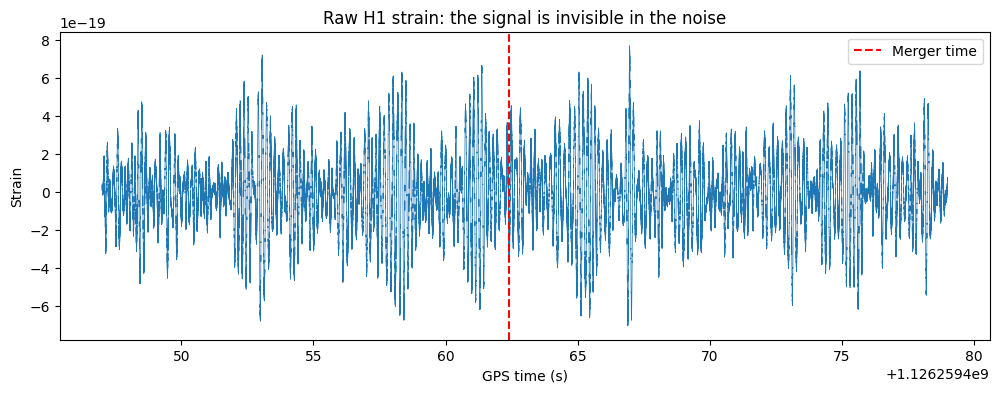

In [2]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(strain_h1.sample_times, strain_h1, lw=0.5)
ax.axvline(merger.time, color="red", ls="--", label="Merger time")
ax.set_xlabel("GPS time (s)")
ax.set_ylabel("Strain")
ax.set_title("Raw H1 strain: the signal is invisible in the noise")
ax.legend()
plt.savefig("../outputs/plots/01_raw_strain.png", dpi=200, bbox_inches="tight")
plt.show()

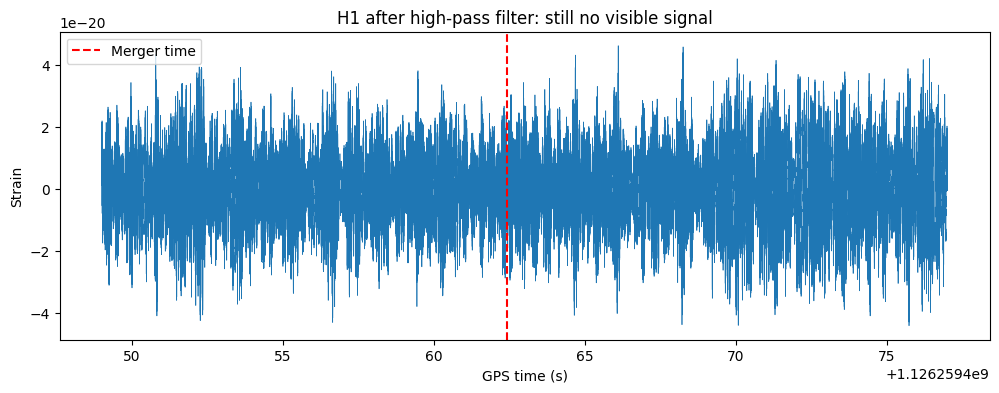

In [3]:
from pycbc.filter import highpass, resample_to_delta_t

def condition(strain):
    s = highpass(strain, 15.0)                 # remove the low-frequency rumble
    s = resample_to_delta_t(s, 1.0/2048)       # 4096 Hz -> 2048 Hz
    return s.crop(2, 2)                        # trim filter edge effects

cond_h1 = condition(strain_h1)
cond_l1 = condition(strain_l1)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(cond_h1.sample_times, cond_h1, lw=0.5)
ax.axvline(merger.time, color="red", ls="--", label="Merger time")
ax.set_xlabel("GPS time (s)")
ax.set_ylabel("Strain")
ax.set_title("H1 after high-pass filter: still no visible signal")
ax.legend()
plt.savefig("../outputs/plots/02_highpassed_strain.png", dpi=200, bbox_inches="tight")
plt.show()

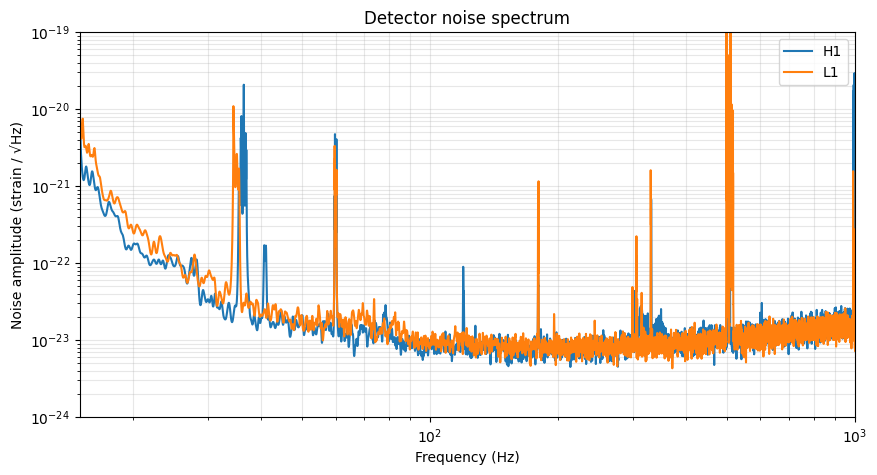

In [4]:
from pycbc.psd import interpolate, inverse_spectrum_truncation

def get_psd(cond):
    psd = cond.psd(4)                                    # average noise power in 4 s chunks
    psd = interpolate(psd, cond.delta_f)
    psd = inverse_spectrum_truncation(
        psd, int(4 * cond.sample_rate), low_frequency_cutoff=15
    )
    return psd

psd_h1 = get_psd(cond_h1)
psd_l1 = get_psd(cond_l1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.loglog(psd_h1.sample_frequencies, psd_h1 ** 0.5, label="H1")
ax.loglog(psd_l1.sample_frequencies, psd_l1 ** 0.5, label="L1")
ax.set_xlim(15, 1000)
ax.set_ylim(1e-24, 1e-19)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Noise amplitude (strain / √Hz)")
ax.set_title("Detector noise spectrum")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.savefig("../outputs/plots/03_noise_spectrum.png", dpi=200, bbox_inches="tight")
plt.show()

In [5]:
from pycbc.waveform import get_td_waveform
from pycbc.filter import matched_filter
import itertools
import pickle
from pathlib import Path
import numpy as np

def peak_snr(cond, psd, m1, m2, s1=0.0, s2=0.0):
    hp, _ = get_td_waveform(approximant="SEOBNRv4_opt",
                            mass1=m1, mass2=m2, spin1z=s1, spin2z=s2,
                            delta_t=cond.delta_t, f_lower=20)
    hp.resize(len(cond))
    template = hp.cyclic_time_shift(hp.start_time)
    snr = matched_filter(template, cond, psd=psd, low_frequency_cutoff=20)
    snr = snr.crop(9, 4)
    return float(abs(snr).max())      # whole data stretch, no merger time used

def chirp_mass(m1, m2):
    return (m1 * m2) ** 0.6 / (m1 + m2) ** 0.2

t0 = float(merger.time)
m1_grid = list(range(30, 51, 1))      # 30 to 50
m2_grid = list(range(24, 45, 1))      # 24 to 44

# --- search, or load saved results if they exist ---
cache = Path("../outputs/bank_results.pkl")

if cache.exists() and cache.stat().st_size > 0:
    with open(cache, "rb") as f:
        results = pickle.load(f)
    print(f"Loaded {len(results)} saved results (search skipped)")
else:
    results = {}
    for m1, m2 in itertools.product(m1_grid, m2_grid):
        if m2 > m1:
            continue
        results[(m1, m2)] = (peak_snr(cond_h1, psd_h1, m1, m2),
                             peak_snr(cond_l1, psd_l1, m1, m2))
    tmp = cache.with_suffix(".tmp")
    with open(tmp, "wb") as f:
        pickle.dump(results, f)
    tmp.replace(cache)          # only becomes the real file once fully written
    print(f"Ran search ({len(results)} templates) and saved")

# --- pick the ridge of good fits ---
scores = {k: np.hypot(*v) for k, v in results.items()}
top = max(scores.values())
good = [k for k, s in scores.items() if s > top - 0.5]   # all fits within 0.5 SNR of the best

cms = [chirp_mass(a, b) for a, b in good]
print(f"{len(good)} templates within 0.5 SNR of the best")
print(f"Chirp mass range: {min(cms):.1f} to {max(cms):.1f}  (median {np.median(cms):.1f})")

# For the pipeline, use the template whose chirp mass is closest to the median
best = min(good, key=lambda k: abs(chirp_mass(*k) - np.median(cms)))
print("Representative template:", best)

Loaded 336 saved results (search skipped)
67 templates within 0.5 SNR of the best
Chirp mass range: 29.5 to 32.6  (median 31.0)
Representative template: (44, 29)


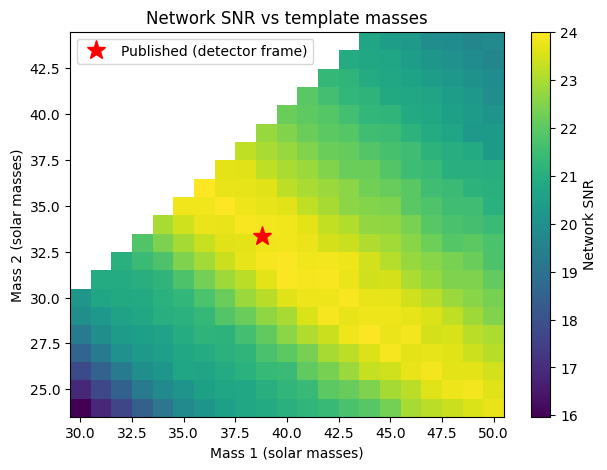

In [6]:
import numpy as np
import matplotlib.pyplot as plt

M1 = sorted(set(k[0] for k in results))
M2 = sorted(set(k[1] for k in results))

grid = np.full((len(M2), len(M1)), np.nan)
for (a, b), (h, l) in results.items():
    grid[M2.index(b), M1.index(a)] = np.hypot(h, l)

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(
    grid, origin="lower", cmap="viridis", aspect="auto",
    extent=[M1[0] - 0.5, M1[-1] + 0.5, M2[0] - 0.5, M2[-1] + 0.5],
)
plt.colorbar(im, label="Network SNR")

# Published masses converted to the detector frame (x 1.09)
ax.plot(35.6 * 1.09, 30.6 * 1.09, marker="*", color="red", markersize=14,
        linestyle="none", label="Published (detector frame)")

ax.set_xlabel("Mass 1 (solar masses)")
ax.set_ylabel("Mass 2 (solar masses)")
ax.set_title("Network SNR vs template masses")
ax.legend(loc="upper left")

plt.savefig("../outputs/plots/06_template_bank.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
from pycbc.waveform import get_td_waveform
from pycbc.filter import matched_filter

def run_matched_filter(cond, psd, m1, m2):
    hp, _ = get_td_waveform(approximant="SEOBNRv4_opt",
                            mass1=m1, mass2=m2,
                            delta_t=cond.delta_t, f_lower=20)
    hp.resize(len(cond))
    template = hp.cyclic_time_shift(hp.start_time)
    snr = matched_filter(template, cond, psd=psd, low_frequency_cutoff=20)
    return snr.crop(9, 4), template      # drop edges corrupted by the filter

snr_h1, template = run_matched_filter(cond_h1, psd_h1, m1=best[0], m2=best[1])
snr_l1, _        = run_matched_filter(cond_l1, psd_l1, m1=best[0], m2=best[1])

for name, snr in [("H1", snr_h1), ("L1", snr_l1)]:
    i = abs(snr).numpy().argmax()
    print(f"{name}: peak SNR = {abs(snr[i]):.1f} at GPS {snr.sample_times[i]:.3f}")

H1: peak SNR = 19.4 at GPS 1126259462.425
L1: peak SNR = 13.8 at GPS 1126259462.417


In [8]:
import time
t_start = time.time()
peak_snr(cond_h1, psd_h1, 38, 34)
print(f"One template, one detector: {time.time() - t_start:.1f} s")

One template, one detector: 0.8 s


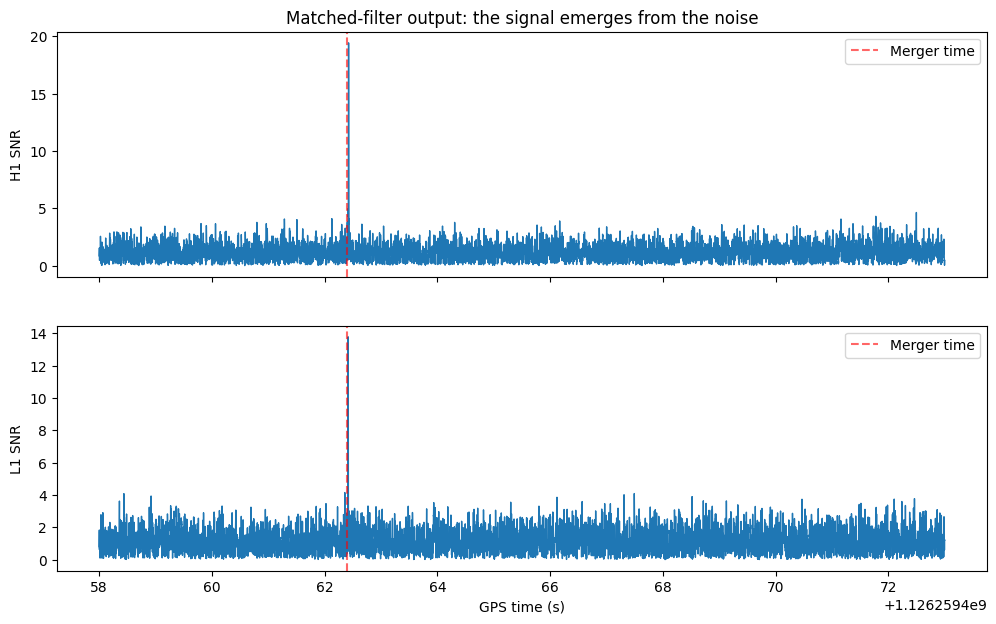

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, snr, name in zip(axes, [snr_h1, snr_l1], ["H1", "L1"]):
    ax.plot(snr.sample_times, abs(snr), lw=1)
    ax.axvline(merger.time, color="red", ls="--", alpha=0.6, label="Merger time")
    ax.set_ylabel(f"{name} SNR")
    ax.legend()
axes[0].set_title("Matched-filter output: the signal emerges from the noise")
axes[1].set_xlabel("GPS time (s)")
plt.savefig("../outputs/plots/04_snr.png", dpi=200, bbox_inches="tight")
plt.show()

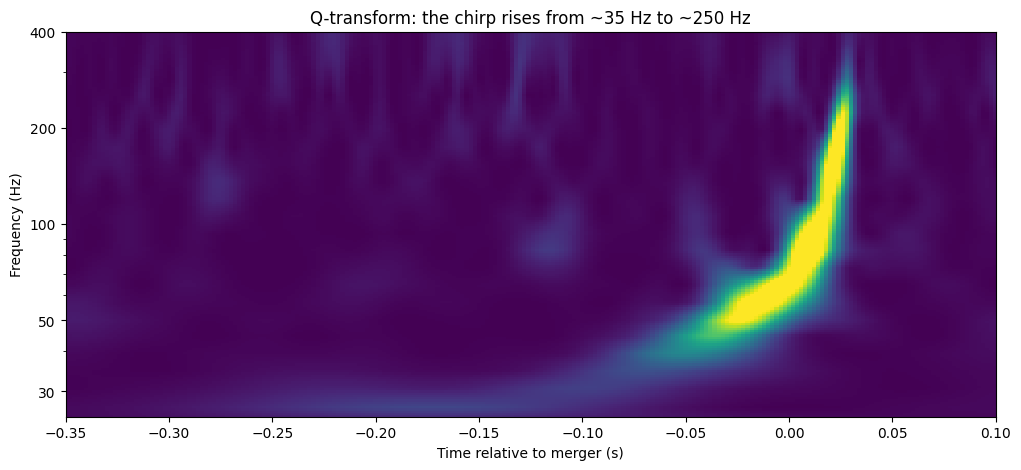

In [10]:
from pycbc.filter import highpass, lowpass_fir, highpass_fir
import numpy as np

def whiten(cond, psd):
    w = (cond.to_frequencyseries() / psd ** 0.5).to_timeseries()
    w = w.highpass_fir(30, 512).lowpass_fir(350, 512)
    return w

white_h1 = whiten(cond_h1, psd_h1)
white_l1 = whiten(cond_l1, psd_l1)

t0 = float(merger.time)
# Use a longer segment, then plot only the middle where edges are clean
seg_long = white_h1.time_slice(t0 - 1.0, t0 + 0.5)
times, freqs, power = seg_long.qtransform(delta_t=0.002, logfsteps=200,
                                          qrange=(8, 8), frange=(20, 500))

# Choose the color scale from the noise, not from the edge blobs
mask = (times - t0 > -0.6) & (times - t0 < 0.3)
vmax = np.percentile(power[:, mask], 99.5)

fig, ax = plt.subplots(figsize=(12, 5))
ax.pcolormesh(times - t0, freqs, power, shading="auto", cmap="viridis",
              vmin=0, vmax=vmax)
ax.set_yscale("log")
ax.set_xlim(-0.35, 0.1)
ax.set_ylim(25, 400)
ax.set_xlabel("Time relative to merger (s)")
ax.set_ylabel("Frequency (Hz)")
ax.set_title("Q-transform: the chirp rises from ~35 Hz to ~250 Hz")
ax.set_yticks([30, 50, 100, 200, 400])
ax.set_yticklabels(["30", "50", "100", "200", "400"])
plt.savefig("../outputs/plots/05_chirp.png", dpi=200, bbox_inches="tight")

plt.show()

In [11]:
bm1, bm2 = best
for s in [-0.1, -0.05, 0.0, 0.05, 0.1]:
    h = peak_snr(cond_h1, psd_h1, bm1, bm2, s, s)
    l = peak_snr(cond_l1, psd_l1, bm1, bm2, s, s)
    print(f"spin {s:+.2f}: H1 = {h:.1f}, L1 = {l:.1f}, network = {np.hypot(h, l):.1f}")

spin -0.10: H1 = 19.2, L1 = 13.1, network = 23.2
spin -0.05: H1 = 19.5, L1 = 13.4, network = 23.7
spin +0.00: H1 = 19.4, L1 = 13.8, network = 23.8
spin +0.05: H1 = 19.2, L1 = 13.8, network = 23.7
spin +0.10: H1 = 18.9, L1 = 13.6, network = 23.3


In [12]:
from scipy.io import wavfile
from scipy.signal import resample_poly
from IPython.display import Audio, display
from pathlib import Path

Path("../outputs/audio").mkdir(parents=True, exist_ok=True)

def make_audio_single(white, t0, name, sig_window=(-0.8, 0.25), speed=2, pad_sec=1.5):
    rate = int(white.sample_rate)                      # 2048 Hz
    pad_data = pad_sec * speed                         # padding length in data seconds

    # One continuous stretch: real noise | chirp | real noise
    seg = white.time_slice(t0 + sig_window[0] - pad_data, t0 + sig_window[1] + pad_data)
    x = np.array(seg, dtype=float)

    # Normalize by the loudest point near the merger, so the noise stays at its
    # true level relative to the signal
    i_a = int(pad_data * rate)
    i_b = len(x) - int(pad_data * rate)
    x = x / np.abs(x[i_a:i_b]).max()
    x = np.clip(x, -1, 1)

    n = int(0.05 * rate)                               # 50 ms fades at the very ends
    x[:n] *= np.linspace(0, 1, n)
    x[-n:] *= np.linspace(1, 0, n)

    y = resample_poly(x, 44100, rate * speed)          # pitch x speed
    y = y / np.abs(y).max() * 0.9

    wavfile.write(f"../outputs/audio/{name}.wav", 44100, (y * 32767).astype(np.int16))
    sig_len = (sig_window[1] - sig_window[0]) / speed
    print(f"{name}: {len(y)/44100:.1f} s total, signal part {sig_len:.2f} s "
          f"(from {pad_sec:.1f} s to {pad_sec + sig_len:.1f} s)")
    return y

audio_h1_single = make_audio_single(white_h1, t0, "gw150914_H1_single")
display(Audio(audio_h1_single, rate=44100))

gw150914_H1_single: 3.5 s total, signal part 0.53 s (from 1.5 s to 2.0 s)


In [13]:
from scipy.io import wavfile
from scipy.signal import resample_poly
from IPython.display import Audio, display
from pathlib import Path

Path("../outputs/audio").mkdir(parents=True, exist_ok=True)

def make_audio_enhanced(name, sig_window=(-0.8, 0.25), speed=2, pad_sec=1.5, pad_gain=0.3):
    rate = int(white_h1.sample_rate)                   # 2048 Hz
    pad_data = pad_sec * speed
    a = t0 + sig_window[0] - pad_data
    b = t0 + sig_window[1] + pad_data

    h = np.array(white_h1.time_slice(a, b), dtype=float)
    l = np.array(white_l1.time_slice(a, b), dtype=float)

    # 1. Align L1 to H1 using the merger region, then add them
    m = int((t0 - a) * rate)                           # merger index
    i0, i1 = m - int(0.10 * rate), m + int(0.03 * rate)
    best_c, best_sh = 0.0, 0
    for sh in range(-24, 25):                          # about +/- 12 ms
        c = np.dot(h[i0:i1], np.roll(l, sh)[i0:i1])
        if abs(c) > abs(best_c):
            best_c, best_sh = c, sh
    sign = 1.0 if best_c > 0 else -1.0
    print(f"L1 shift: {best_sh / rate * 1000:+.1f} ms, inverted: {sign < 0}")
    x = h + sign * np.roll(l, best_sh)

    # 2. Normalize by the chirp section so noise keeps its true level relative to it
    i_a = int(pad_data * rate)
    i_b = len(x) - int(pad_data * rate)
    x = x / np.abs(x[i_a:i_b]).max()

    # 3. Turn the background down outside the chirp, with smooth ramps
    env = np.ones(len(x))
    env[:i_a] = pad_gain
    env[i_b:] = pad_gain
    ramp = int(0.3 * rate)
    env = np.convolve(env, np.ones(ramp) / ramp, mode="same")
    x = np.clip(x * env, -1, 1)

    n = int(0.05 * rate)                               # 50 ms fades at the very ends
    x[:n] *= np.linspace(0, 1, n)
    x[-n:] *= np.linspace(1, 0, n)

    y = resample_poly(x, 44100, rate * speed)
    y = y / np.abs(y).max() * 0.9
    wavfile.write(f"../outputs/audio/{name}.wav", 44100, (y * 32767).astype(np.int16))
    print(f"{name}: {len(y)/44100:.1f} s total")
    return y

audio_enh = make_audio_enhanced("gw150914_combined_enhanced")
display(Audio(audio_enh, rate=44100))

L1 shift: +7.3 ms, inverted: True
gw150914_combined_enhanced: 3.5 s total


In [14]:
from pycbc.waveform import get_td_waveform

# Same settings as the data files
speed, pad_sec = 2, 1.5
sig_window = (-0.8, 0.25)                      # data seconds around the merger
sr = 44100

# 1. Your own template from the bank search
fs = int(white_h1.sample_rate)
hp, hc = get_td_waveform(approximant="SEOBNRv4_opt",
                         mass1=best[0], mass2=best[1],
                         delta_t=1.0 / fs, f_lower=20)
print("Model template masses (detector frame):", best)

hpa, hca = np.array(hp), np.array(hc)
amp = np.hypot(hpa, hca)
phase = np.unwrap(np.arctan2(hca, hpa))
if phase[-1] < phase[0]:
    phase = -phase

peak = amp.argmax()
amp = amp / amp[peak]
t_data = (np.arange(len(amp)) - peak) / fs      # 0 = merger peak

# 2. Output timeline, same total length as the data files
total = 2 * pad_sec + (sig_window[1] - sig_window[0]) / speed
t_out = np.arange(int(total * sr)) / sr
t_merge = pad_sec + (-sig_window[0]) / speed    # merger position in the clip (1.9 s)

# map output time -> data time (no stretching, only speed)
td = (t_out - t_merge) * speed
inside = (td >= t_data[0]) & (td <= 0.005)      # stop 5 ms after the peak (no ringdown)

y = np.zeros(len(t_out))
A = np.interp(td[inside], t_data, amp)
P = np.interp(td[inside], t_data, phase)
y[inside] = A * np.sin(P - P[0])

# 3. Fade in/out, normalize, save
idx = np.where(inside)[0]
n1, n2 = int(0.02 * sr), int(0.03 * sr)
y[idx[0]: idx[0] + n1] *= np.linspace(0, 1, n1)
y[idx[-1] - n2 + 1: idx[-1] + 1] *= np.linspace(1, 0, n2)
audio_model = y / np.abs(y).max() * 0.9

wavfile.write("../outputs/audio/gw150914_model_clean.wav", sr,
              (audio_model * 32767).astype(np.int16))
print(f"Model audio: {len(audio_model)/sr:.1f} s total, chirp {len(idx)/sr:.2f} s, "
      f"merger at {t_merge:.1f} s")
display(Audio(audio_model, rate=sr))

Model template masses (detector frame): (44, 29)
Model audio: 3.5 s total, chirp 0.30 s, merger at 1.9 s


In [15]:
import numpy as np

GM_c2 = 1.4766          # km, G*Msun/c^2
Msun_kg, c = 1.989e30, 2.998e8

# Published GWTC-1 values (source frame)
m1, m2   = 35.6, 30.6   # initial black holes (solar masses)
m_f      = 63.1         # final black hole
chi_f    = 0.69         # final spin (dimensionless)

def area_schwarzschild(m):            # non-spinning: A = 16 pi (GM/c^2)^2
    return 16 * np.pi * (m * GM_c2) ** 2

def area_kerr(m, chi):                # spinning: A = 8 pi (GM/c^2)^2 (1 + sqrt(1 - chi^2))
    return 8 * np.pi * (m * GM_c2) ** 2 * (1 + np.sqrt(1 - chi ** 2))

A1, A2 = area_schwarzschild(m1), area_schwarzschild(m2)
A_final = area_kerr(m_f, chi_f)

print(f"Schwarzschild radius, BH1: {2*m1*GM_c2:.1f} km")
print(f"Schwarzschild radius, BH2: {2*m2*GM_c2:.1f} km")
print(f"Final outer horizon radius: {m_f*GM_c2*(1+np.sqrt(1-chi_f**2)):.1f} km")
print()
print(f"A1      = {A1:,.0f} km^2")
print(f"A2      = {A2:,.0f} km^2")
print(f"A1 + A2 = {A1+A2:,.0f} km^2")
print(f"A_final = {A_final:,.0f} km^2")
print(f"Ratio A_final / (A1 + A2) = {A_final/(A1+A2):.2f}")
print("Area theorem check (A_final > A1 + A2):", A_final > A1 + A2)
print()

dm = m1 + m2 - m_f
print(f"Mass sum: {m1+m2:.1f}  vs final {m_f:.1f}  ->  {dm:.1f} Msun radiated")
print(f"Energy radiated: {dm*Msun_kg*c**2:.2e} J")

# Rough sensitivity check: low end of the published final mass and spin
A_low = area_kerr(60.1, 0.65)
print(f"\nPessimistic final (60.1 Msun, spin 0.65): {A_low:,.0f} km^2  "
      f"-> still > A1+A2: {A_low > A1 + A2}")

Schwarzschild radius, BH1: 105.1 km
Schwarzschild radius, BH2: 90.4 km
Final outer horizon radius: 160.6 km

A1      = 138,898 km^2
A2      = 102,622 km^2
A1 + A2 = 241,519 km^2
A_final = 376,109 km^2
Ratio A_final / (A1 + A2) = 1.56
Area theorem check (A_final > A1 + A2): True

Mass sum: 66.2  vs final 63.1  ->  3.1 Msun radiated
Energy radiated: 5.54e+47 J

Pessimistic final (60.1 Msun, spin 0.65): 348,346 km^2  -> still > A1+A2: True


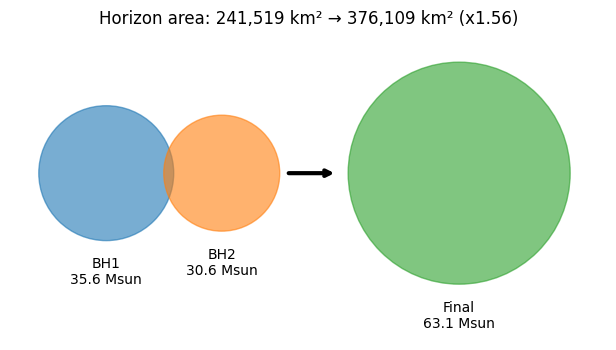

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))

# area-equivalent radius r = sqrt(A / 4 pi), so circle areas compare fairly
r = lambda A: np.sqrt(A / (4 * np.pi))
r1, r2, rf = r(A1), r(A2), r(A_final)

for x, rad, label, col in [(-300, r1, f"BH1\n{m1} Msun", "tab:blue"),
                           (-120, r2, f"BH2\n{m2} Msun", "tab:orange"),
                           (250, rf, f"Final\n{m_f} Msun", "tab:green")]:
    ax.add_patch(plt.Circle((x, 0), rad, color=col, alpha=0.6))
    ax.text(x, -rad - 25, label, ha="center", va="top")

ax.annotate("", xy=(60, 0), xytext=(-20, 0),
            arrowprops=dict(arrowstyle="->", lw=3))
ax.set_xlim(-450, 480); ax.set_ylim(-260, 220)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title(f"Horizon area: {A1+A2:,.0f} km² → {A_final:,.0f} km² (x{A_final/(A1+A2):.2f})")
plt.savefig("../outputs/plots/07_event_horizons.png", dpi=200, bbox_inches="tight")
plt.show()

In [18]:
import numpy as np
from pycbc.waveform import get_td_waveform
from pycbc.filter import matched_filter

fs = int(white_h1.sample_rate)
T_START, T_END = -3.0, 1.0
seg = white_h1.time_slice(t0 + T_START, t0 + T_END)           # whitened data

# --- whitened template for your chosen masses ---
hp, hc = get_td_waveform(approximant="SEOBNRv4_opt", mass1=best[0], mass2=best[1],
                         delta_t=1.0 / fs, f_lower=20)
n_hp = len(hp)
pk = int(np.hypot(np.array(hp), np.array(hc)).argmax())       # merger = peak of the RAW waveform
hp.resize(len(cond_h1))
tw = np.array(whiten(hp, psd_h1))

TAIL = 0.05
n_before = min(int(0.55 * fs), pk)                            # never start before index 0
template = tw[pk - n_before: pk + int(TAIL * fs)]
print(f"waveform: {n_hp / fs:.2f} s | merger index: {pk} | template samples: {len(template)}")
assert len(template) > 100, "template is empty or too short. Paste the printed line above."

# --- your own PyCBC SNR curve for the same masses ---
hp2, _ = get_td_waveform(approximant="SEOBNRv4_opt", mass1=best[0], mass2=best[1],
                         delta_t=cond_h1.delta_t, f_lower=20)
hp2.resize(len(cond_h1))
tmpl2 = hp2.cyclic_time_shift(hp2.start_time)
snr_py = matched_filter(tmpl2, cond_h1, psd=psd_h1, low_frequency_cutoff=20).crop(9, 4)

np.savez("../data/mf_animation_inputs.npz",
         data=np.array(seg), template=template, fs=fs, t_start=T_START, tail_s=TAIL,
         masses=np.array(best), snr_ref=float(np.abs(snr_py).max()),
         pyc_t=np.array(snr_py.sample_times) - t0, pyc_snr=np.abs(np.array(snr_py)))
print("saved. PyCBC peak SNR:", round(float(np.abs(snr_py).max()), 1))

waveform: 0.74 s | merger index: 1238 | template samples: 1228
saved. PyCBC peak SNR: 19.4
